In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = Path("C:/final")

record = pd.read_csv(
    PROJECT_ROOT / "data" / "record_except_168.csv",
    encoding="utf-8-sig",
)
port_month = pd.read_csv(
    PROJECT_ROOT / "data" / "port_month.csv",
    encoding="cp949",
)

piers = ["1부두", "2부두", "3부두", "4부두", "5부두"]
port_month.columns = [
    "연도", "월", "1부두", "2부두", "3부두", "4부두", "5부두",
    "6부두", "7부두", "단위",
]

record["입항일시"] = pd.to_datetime(record["입항일시"])
record["연도"] = record["입항일시"].dt.year
record["재항시간"] = pd.to_numeric(record["재항시간"], errors="coerce")
record["부두"] = record["계선장소"].str.extract(
    r"([1-5])부두", expand=False
).map(lambda pier: f"{pier}부두" if pd.notna(pier) else pd.NA)

annual_teu = (
    port_month.loc[port_month["연도"].between(2022, 2025), ["연도", *piers]]
    .groupby("연도", as_index=False)
    .sum()
    .melt(id_vars="연도", var_name="부두", value_name="처리TEU")
)
annual_teu["처리TEU"] = annual_teu["처리TEU"] * 1000

stay_hours = (
    record.loc[record["부두"].isin(piers)]
    .groupby(["연도", "부두"], as_index=False)["재항시간"]
    .sum()
)

productivity = annual_teu.merge(stay_hours, on=["연도", "부두"])
productivity["체류생산성"] = productivity["처리TEU"] / productivity["재항시간"]
productivity = productivity.sort_values(["부두", "연도"])


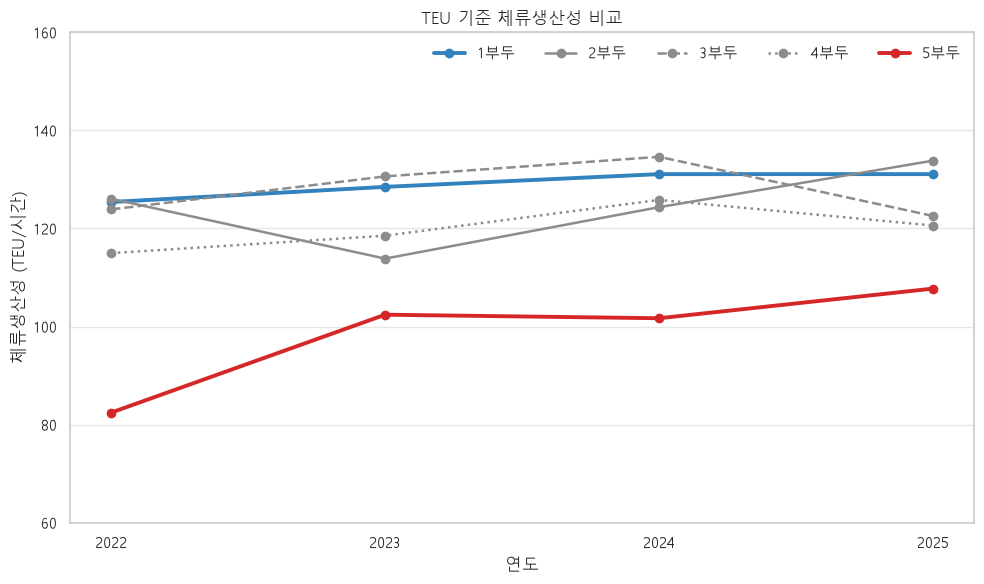

In [2]:
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

fig, ax = plt.subplots(figsize=(10, 6))
colors = {
    "1부두": "#3182bd",
    "2부두": "#8c8c8c",
    "3부두": "#8c8c8c",
    "4부두": "#8c8c8c",
    "5부두": "#d62728",
}
linestyles = {
    "1부두": "-",
    "2부두": "-",
    "3부두": "--",
    "4부두": ":",
    "5부두": "-",
}

for pier in piers:
    pier_data = productivity[productivity["부두"] == pier]
    ax.plot(
        pier_data["연도"],
        pier_data["체류생산성"],
        label=pier,
        color=colors[pier],
        linestyle=linestyles[pier],
        linewidth=2.8 if pier in ["1부두", "5부두"] else 1.8,
        marker="o",
        markersize=6,
    )

ax.set_title("TEU 기준 체류생산성 비교")
ax.set_xlabel("연도")
ax.set_ylabel("체류생산성 (TEU/시간)")
ax.set_ylim(60, 160)
ax.set_yticks(range(60, 161, 20))
ax.set_xticks([2022, 2023, 2024, 2025])
ax.grid(axis="x", visible=False)
ax.legend(ncol=5, frameon=False)
plt.tight_layout()
plt.show()
